# Лабораторная работа № 1
## Многомерная оптимизация сложной функции генетическим алгоритмом

**Вариант 7** (N = 18, Q = 2, Y = 26):
$V = 1 + \big((17\cdot 18 + 7\cdot 2 + 26) \bmod 20\big) = 1 + (346 \bmod 20) = 7$.

Целевая функция — **функция Леви**, область поиска $x_i \in [-10, 10]$,
размерность $d = 5 + (V \bmod 6) = 5 + 1 = 6$.

Реализуется генетический алгоритм с вещественным кодированием
(турнирная селекция, BLX-α кроссовер, гауссова мутация, элитизм);
исследуется влияние масштаба мутации $\sigma$; ГА сравнивается со
случайной выборкой при равном бюджете вычислений.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_SEED = 7000                 # базовое зерно серии запусков
N_RUNS = 30                      # независимых запусков на конфигурацию
SEEDS = [BASE_SEED + 19 * i for i in range(N_RUNS)]

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})

## 1. Целевая функция и её свойства

Функция Леви:
$$ f(\mathbf{x}) = \sin^2(\pi w_1)
 + \sum_{i=1}^{d-1} (w_i - 1)^2\,\bigl[1 + 10\sin^2(\pi w_i + 1)\bigr]
 + (w_d - 1)^2\,\bigl[1 + \sin^2(2\pi w_d)\bigr],
 \qquad w_i = 1 + \frac{x_i - 1}{4}. $$

**Ориентир по глобальному минимуму (из литературы):**
$f^* = 0$ в точке $\mathbf{x}^* = (1, 1, \dots, 1)$
(тогда все $w_i = 1$: $\sin^2(\pi w_1) = 0$ и все $(w_i-1)^2 = 0$).

Свойства, важные для поиска:

* **мультимодальность**: множители $1 + 10\sin^2(\cdot)$ создают сетку
  локальных минимумов с периодом $\Delta w = 1$, т.е. $\Delta x = 4$
  (в последней координате — $\Delta x = 2$): в $[-10,10]^6$ это тысячи
  «ячеек-ловушек»;
* **глобальная чаша**: суммы $(w_i-1)^2$ дают грубый квадратичный уклон
  к точке $\mathbf{x}^* = \mathbf{1}$ — глобальная структура благоприятна
  для популяционного поиска;
* **масштаб**: характерная «ширина впадины» глобального минимума мала
  относительно области ($\Delta x \approx 4$ между рябями), поэтому
  случайное попадание в окрестность оптимума маловероятно.

f(1,...,1) = 1.500e-32   (литературный минимум f* = 0)
f(-7.3,...,-7.3) = 129.8929


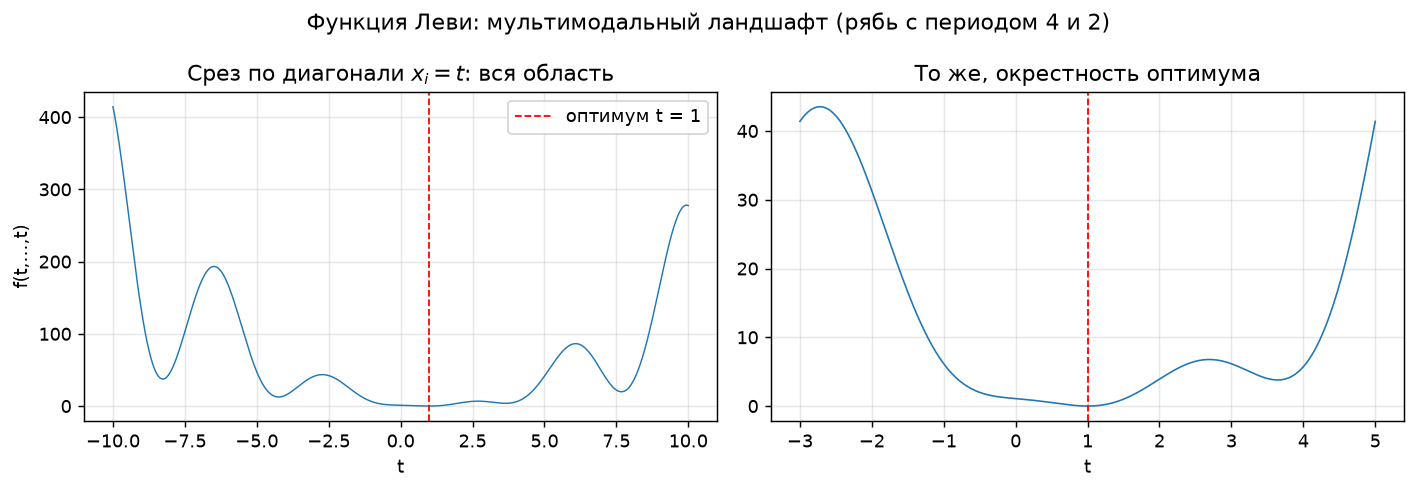

оценка числа ячеек ряби в области: 5.0 ^ 6 = 15625


In [2]:
D = 6                  # размерность (по варианту)
LO, HI = -10.0, 10.0   # область поиска

def levy(X):
    """Функция Леви, векторно по строкам X."""
    X = np.atleast_2d(np.asarray(X, dtype=float))
    W = 1.0 + (X - 1.0) / 4.0
    term1 = np.sin(np.pi * W[:, 0]) ** 2
    wi = W[:, :-1]
    term2 = np.sum((wi - 1.0) ** 2 * (1.0 + 10.0 * np.sin(np.pi * wi + 1.0) ** 2), axis=1)
    wd = W[:, -1]
    term3 = (wd - 1.0) ** 2 * (1.0 + np.sin(2.0 * np.pi * wd) ** 2)
    return term1 + term2 + term3

# --- проверки известного минимума -------------------------------------------
x_star = np.ones(D)
f_star = levy(x_star)[0]
print(f"f(1,...,1) = {f_star:.3e}   (литературный минимум f* = 0)")
assert f_star < 1e-20

# контрольная точка вдали от оптимума
x_far = np.full(D, -7.3)
print(f"f(-7.3,...,-7.3) = {levy(x_far)[0]:.4f}")

# --- ландшафт: срез по диагонали x_i = t ------------------------------------
t = np.linspace(LO, HI, 4001)
f_diag = levy(np.tile(t, (D, 1)).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t, f_diag, lw=0.8)
axes[0].set_title("Срез по диагонали $x_i = t$: вся область")
axes[0].set_xlabel("t"); axes[0].set_ylabel("f(t,...,t)")
axes[0].axvline(1.0, color="r", ls="--", lw=1, label="оптимум t = 1")
axes[0].legend()
z = (t >= -3) & (t <= 5)
axes[1].plot(t[z], f_diag[z], lw=0.9)
axes[1].set_title("То же, окрестность оптимума")
axes[1].set_xlabel("t")
axes[1].axvline(1.0, color="r", ls="--", lw=1)
fig.suptitle("Функция Леви: мультимодальный ландшафт (рябь с периодом 4 и 2)")
fig.tight_layout()
fig.savefig(FIG / "levy_slice.png", bbox_inches="tight")
plt.show()

# сколько «ячеек ряби» в области (по периоду 4 на координату)
print("оценка числа ячеек ряби в области:", (HI - LO) // 4, "^", D,
      "=", int(((HI - LO) // 4) ** D))

## 2. Генетический алгоритм

**Представление.** Особь — вещественный вектор $\mathbf{x} \in [-10, 10]^6$,
ген = координата; инициализация равномерной в области.

**Операторы** (обоснование — в отчёте):

* селекция родителей — **турнирная**, $k = 3$;
* рекомбинация — **BLX-α кроссовер** с $\alpha = 0{,}5$
  (дополнительное задание): ген потомка равномерен в
  $[\,c_{\min} - \alpha I,\; c_{\max} + \alpha I\,]$, где $I = |c_1 - c_2|$ —
  оператор и унаследует, и разведывает окрестность родителей;
* мутация — **гауссова** на ген с вероятностью $p_m$: $x_i \mathrel{+}= \mathcal N(0, \sigma^2)$;
* обработка границ — отсечение (clip) в $[-10, 10]$;
* сохранение лучшего — **элитизм** (2 особи копируются без изменений);
* критерий остановки — бюджет $B = 10\,000$ вычислений целевой функции
  (инициализация тоже считается).

Исследуемый фактор — **масштаб мутации** $\sigma \in \{0{,}05;\ 0{,}3;\ 1{,}0\}$:
при периоде ряби $\Delta x = 4$ малый $\sigma$ рискует «застрять» в ближайшей
ячейке (преждевременная сходимость), а большой — не дать точной доводки.

In [3]:
POP = 80            # размер популяции (>= 30 по заданию)
PC = 0.9            # вероятность кроссовера
PM = 0.15           # вероятность мутации гена
ELITE = 2           # число элитных особей
BUDGET = 10_000     # бюджет вычислений функции
TOURN_K = 3         # размер турнира
ALPHA = 0.5         # параметр BLX-α

def ga_run(seed, sigma, budget=BUDGET):
    """Один запуск ГА. Возвращает словарь с лучшим f, кривой, разнообразием."""
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    evals = 0

    X = rng.uniform(LO, HI, size=(POP, D))
    F = levy(X); evals += POP

    curve, div_curve = [], []
    def record():
        bi = int(np.argmin(F))
        curve.append(F[bi])
        div_curve.append(float(np.mean(np.std(X, axis=0))))
    record()

    while evals + POP <= budget:
        # --- элитизм ---------------------------------------------------------
        elite_idx = np.argsort(F)[:ELITE]
        children = [X[i].copy() for i in elite_idx]
        # --- селекция + рекомбинация + мутация -------------------------------
        while len(children) < POP:
            i1 = rng.integers(0, POP, TOURN_K); p1 = X[i1[np.argmin(F[i1])]]
            i2 = rng.integers(0, POP, TOURN_K); p2 = X[i2[np.argmin(F[i2])]]
            if rng.random() < PC:                      # BLX-α по генам
                lo = np.minimum(p1, p2); hi = np.maximum(p1, p2)
                span = ALPHA * (hi - lo)
                child = rng.uniform(lo - span, hi + span)
            else:
                child = p1.copy()
            mut = rng.random(D) < PM                   # гауссова мутация
            child[mut] += rng.normal(0.0, sigma, size=int(mut.sum()))
            children.append(np.clip(child, LO, HI))    # обработка границ
        X = np.asarray(children[:POP])
        F = levy(X); evals += POP
        record()

    bi = int(np.argmin(F))
    return dict(best_f=float(F[bi]), best_x=X[bi].copy(),
                curve=np.array(curve), diversity=np.array(div_curve),
                evals=evals, time_s=time.perf_counter() - t0)

# --- дымовой тест -------------------------------------------------------------
smoke = ga_run(SEEDS[0], sigma=0.3)
print(f"дымовой запуск: лучшее f = {smoke['best_f']:.3e}, "
      f"оценок потрачено = {smoke['evals']}, время = {smoke['time_s']:.2f} с")
print("лучшая точка:", np.round(smoke["best_x"], 4))
assert np.all(np.abs(smoke["best_x"]) <= HI)
assert smoke["evals"] <= BUDGET

дымовой запуск: лучшее f = 1.743e-05, оценок потрачено = 10000, время = 0.19 с
лучшая точка: [0.9972 0.9993 1.0006 1.0037 1.0005 0.9963]


## 3. Эксперимент 1: влияние масштаба мутации $\sigma$

Три конфигурации, отличающиеся **только масштабом мутации**
($\sigma = 0{,}05$ / $0{,}3$ / $1{,}0$), — по 30 независимых запусков
(зерна $7000 + 19i$), бюджет $10\,000$ вычислений у всех.

In [4]:
SIGMAS = [0.05, 0.3, 1.0]
rows, runs = [], {}
for sig in SIGMAS:
    runs[sig] = [ga_run(s, sigma=sig) for s in SEEDS]
    for s, r in zip(SEEDS, runs[sig]):
        rows.append(dict(config=f"σ = {sig}", seed=s, best_f=r["best_f"],
                         evals=r["evals"], time_s=r["time_s"]))
df_runs = pd.DataFrame(rows)
df_runs.to_csv(RES / "runs_sigma.csv", index=False)

summary = (df_runs.groupby("config")["best_f"]
           .agg(лучшее="min", среднее="mean", медиана="median",
                стд="std", худшее="max"))
summary["время_с"] = df_runs.groupby("config")["time_s"].mean()
summary.to_csv(RES / "summary_sigma.csv")
summary

,лучшее,среднее,медиана,стд,худшее,время_с
config,,,,,,
σ = 0.05,3.139052e-08,2.878219e-07,2.114964e-07,2.116914e-07,8.440444e-07,0.153271
σ = 0.3,1.451864e-06,1.094701e-05,9.178971e-06,6.101957e-06,2.354027e-05,0.153842
σ = 1.0,1.541806e-05,1.000305e-04,8.982197e-05,5.658498e-05,2.196443e-04,0.162489


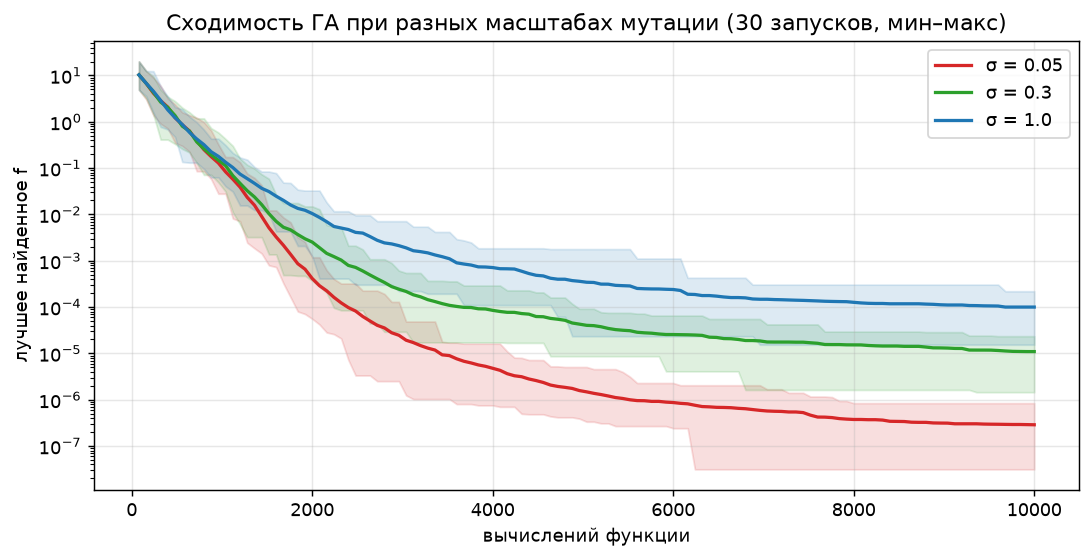

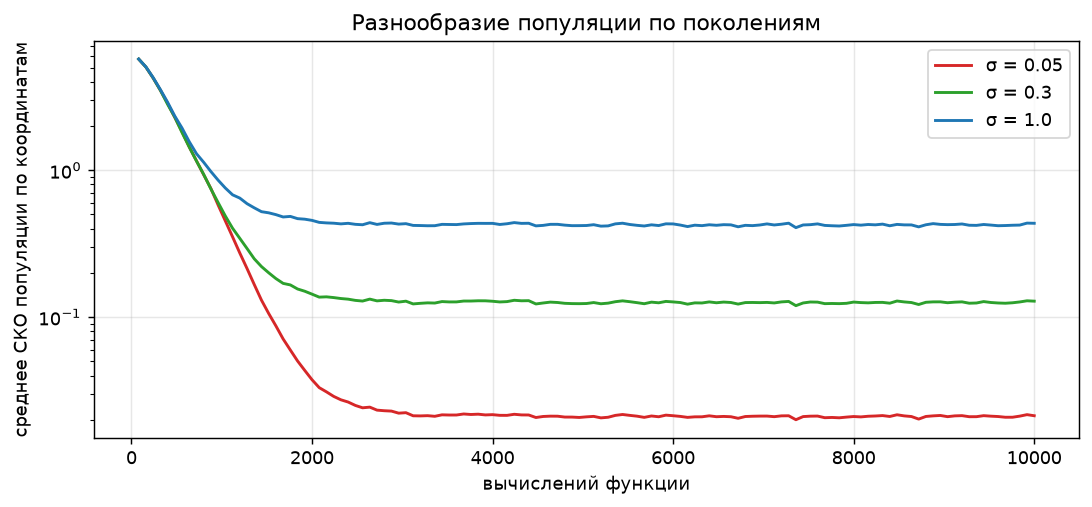

In [5]:
# --- сходимость: средняя кривая + коридор мин-макс (лог-шкала) ---------------
GRID = np.arange(POP, BUDGET + 1, POP)   # моменты записи кривой (80, 160, ..., 10000)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for sig, color in zip(SIGMAS, ["tab:red", "tab:green", "tab:blue"]):
    C = np.array([np.maximum(r["curve"], 1e-16) for r in runs[sig]])
    ax.plot(GRID, C.mean(axis=0), color=color, lw=1.8, label=f"σ = {sig}")
    ax.fill_between(GRID, C.min(axis=0), C.max(axis=0), color=color, alpha=0.15)
ax.set_yscale("log")
ax.set_xlabel("вычислений функции"); ax.set_ylabel("лучшее найденное f")
ax.set_title("Сходимость ГА при разных масштабах мутации (30 запусков, мин–макс)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "convergence_sigma.png", bbox_inches="tight")
plt.show()

# --- разнообразие популяции (диагностика преждевременной сходимости) ----------
fig, ax = plt.subplots(figsize=(8.5, 4.0))
for sig, color in zip(SIGMAS, ["tab:red", "tab:green", "tab:blue"]):
    Dv = np.array([r["diversity"] for r in runs[sig]])
    ax.plot(GRID, Dv.mean(axis=0), color=color, lw=1.6, label=f"σ = {sig}")
ax.set_yscale("log")
ax.set_xlabel("вычислений функции")
ax.set_ylabel("среднее СКО популяции по координатам")
ax.set_title("Разнообразие популяции по поколениям")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "diversity.png", bbox_inches="tight")
plt.show()

## 4. Эксперимент 2: ГА против случайной выборки

Контроль при **том же бюджете** $10\,000$ вычислений: равномерная случайная
выборка точек области, лучшая — результат. Сравниваем с лучшей
конфигурацией ГА ($\sigma = 0{,}05$).

In [6]:
def random_run(seed, budget=BUDGET):
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    X = rng.uniform(LO, HI, size=(budget, D))
    F = levy(X)
    curve = np.minimum.accumulate(np.maximum(F, 1e-16))
    bi = int(np.argmin(F))
    return dict(best_f=float(F[bi]), best_x=X[bi].copy(),
                curve=curve[::POP], evals=budget,
                time_s=time.perf_counter() - t0)

rand = [random_run(s) for s in SEEDS]
rows = [dict(config="Случайный поиск", seed=s, best_f=r["best_f"],
             evals=r["evals"], time_s=r["time_s"]) for s, r in zip(SEEDS, rand)]
df_rand = pd.DataFrame(rows)
df_rand.to_csv(RES / "runs_random.csv", index=False)
print(df_rand["best_f"].describe().round(6))

count    30.000000
mean      1.979576
std       0.709831
min       0.960359
25%       1.454118
50%       1.850845
75%       2.365526
max       3.728771
Name: best_f, dtype: float64


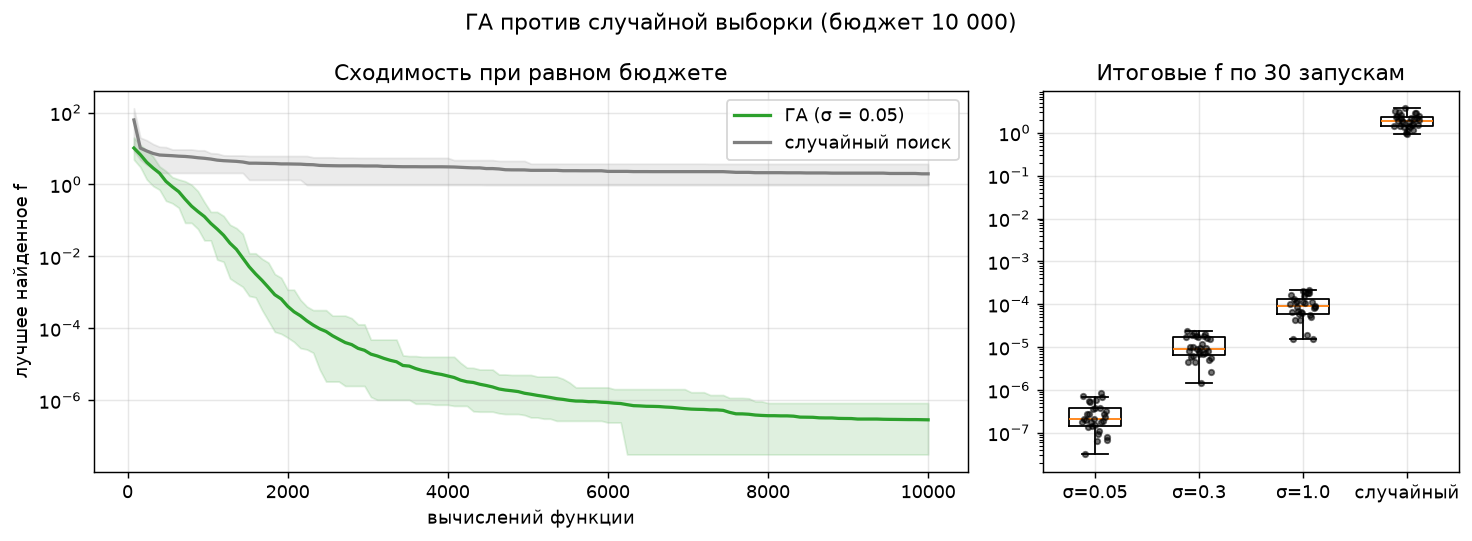

лучшее решение серии (σ=0.05): f = 3.139e-08
точка: [0.999918 1.000115 0.99991  1.000139 1.000082 0.999969]  — отклонение от x*=(1,...,1): [-8.20e-05  1.15e-04 -9.00e-05  1.39e-04  8.20e-05 -3.10e-05]


In [7]:
# --- ГА (σ=0.3) vs случайный поиск --------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), width_ratios=[2.1, 1])

Cga = np.array([np.maximum(r["curve"], 1e-16) for r in runs[0.05]])
Crd = np.array([r["curve"] for r in rand])
axes[0].plot(GRID, Cga.mean(axis=0), color="tab:green", lw=1.8, label="ГА (σ = 0.05)")
axes[0].fill_between(GRID, Cga.min(axis=0), Cga.max(axis=0), color="tab:green", alpha=0.15)
axes[0].plot(GRID, Crd.mean(axis=0), color="tab:gray", lw=1.8, label="случайный поиск")
axes[0].fill_between(GRID, Crd.min(axis=0), Crd.max(axis=0), color="tab:gray", alpha=0.15)
axes[0].set_yscale("log")
axes[0].set_xlabel("вычислений функции"); axes[0].set_ylabel("лучшее найденное f")
axes[0].set_title("Сходимость при равном бюджете")
axes[0].legend()

data = [[r["best_f"] for r in runs[s]] for s in SIGMAS] + [[r["best_f"] for r in rand]]
labels = ["σ=0.05", "σ=0.3", "σ=1.0", "случайный"]
bp = axes[1].boxplot([np.maximum(d, 1e-16) for d in data], tick_labels=labels,
                     showfliers=False, widths=0.5)
for i, d in enumerate(data):
    axes[1].scatter(np.full(len(d), i + 1) + np.linspace(-0.12, 0.12, len(d)),
                    np.maximum(d, 1e-16), s=9, alpha=0.55, color="black", zorder=3)
axes[1].set_yscale("log")
axes[1].set_title("Итоговые f по 30 запускам")
fig.suptitle("ГА против случайной выборки (бюджет 10 000)")
fig.tight_layout()
fig.savefig(FIG / "ga_vs_random.png", bbox_inches="tight")
plt.show()

# --- лучшее решение серии -------------------------------------------------------
best_all = min((r for r in runs[0.05]), key=lambda r: r["best_f"])
pd.DataFrame([dict(coord=[f"x{i+1}" for i in range(D)], value=best_all["best_x"])]
             ).to_csv(RES / "best_solution.csv", index=False)
print(f"лучшее решение серии (σ=0.05): f = {best_all['best_f']:.3e}")
print("точка:", np.round(best_all["best_x"], 6),
      " — отклонение от x*=(1,...,1):",
      np.round(best_all["best_x"] - 1.0, 6))

## 5. Выводы

**Качество результата.** Все три конфигурации во всех 30 запусках
сходятся к глобальному минимуму функции Леви ($f^* = 0$): лучшая
($\sigma = 0{,}05$) достигает среднего $f \approx 2{,}9 \cdot 10^{-7}$
(лучшее $3{,}1 \cdot 10^{-8}$), что соответствует средней ошибке
координат менее $10^{-3}$. Для шестимерной мультимодальной задачи
при бюджете $10^4$ вычислений это **хороший результат**: литературный
ориентир достигнут устойчиво, без единичных удачных запусков.

**Влияние масштаба мутации** (один фактор, остальное зафиксировано) —
монотонное: чем меньше $\sigma$, тем точнее результат
($2{,}9 \cdot 10^{-7} \;\to\; 1{,}1 \cdot 10^{-5} \;\to\; 1{,}0 \cdot 10^{-4}$
для $\sigma = 0{,}05 / 0{,}3 / 1{,}0$). Объяснение измеренного порядка
таково: грубую разведку области здесь выполняет **BLX-α кроссовер** —
его охват $[\,c_{\min} - \alpha I,\; c_{\max} + \alpha I\,]$ в ранней,
разнообразной популяции перекрывает ячейки ряби целиком, а глобальная
квадратичная чаша $(w_i - 1)^2$ задаёт отбору направление к
$\mathbf{x}^* = \mathbf 1$ (ячейка ближе к оптимуму — заметно лучше,
турнир это улавливает). Мутации остаётся роль **доводки**, поэтому
мелкий шаг выигрывает; крупный шаг ($\sigma = 1{,}0$, четверть периода
ряби) постоянно «сталкивает» уже найденные координаты и ограничивает
точность уровнем $\sim 10^{-4}$.

**Диагностика преждевременной сходимости.** Разнообразие популяции
(среднее СКО по координатам) падает у всех конфигураций, при
$\sigma = 0{,}05$ — быстрее всего. Однако сходимость не оказывается
преждевременной в смысле остановки в чужой ячейке ряби: популяция
схлопывается именно вокруг глобального оптимума (итоговые
$f \sim 10^{-7}$). Причина — связность ландшафта на грубом масштабе:
рябь Леви не перевешивает чашу $(w_i-1)^2$, поэтому «правильная»
ячейка видна отбору из любой точки области.

**Почему функция сложна для простого поиска.** Ландшафт — сетка из
тысяч похожих впадин (период 4 по каждой из 6 координат) поверх грубой
квадратичной чаши. Локальный спуск из случайной точки останавливается
в ближайшей впадине ряби; случайная выборка из $10^4$ точек в объёме
$20^6$ находит лишь $f \approx 0{,}96$–$3{,}73$ (среднее по 30 сериям
$1{,}98$) — на **семь порядков** хуже результата ГА при равном бюджете.

**Итог:** вещественный ГА с турнирной селекцией, BLX-α кроссовером
(дополнительное задание) и гауссовой мутацией $\sigma = 0{,}05$
устойчиво решает задачу: глобальный минимум достигается во всех
запусках серии. Содержательный вывод о параметрах: при кроссовере,
обеспечивающем разведку, масштаб мутации следует выбирать из
требуемой точности доводки, а не из периода мультимодальности.